<a href="https://colab.research.google.com/github/pbernard46/MIT-Sloan-Competition/blob/main/Physics_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean detection position: +0.194  (curve center = 0)
KS statistic: 0.107  (5% critical value: 0.215)
Sample is consistent with the curve
Saved particle_detection_sim.png


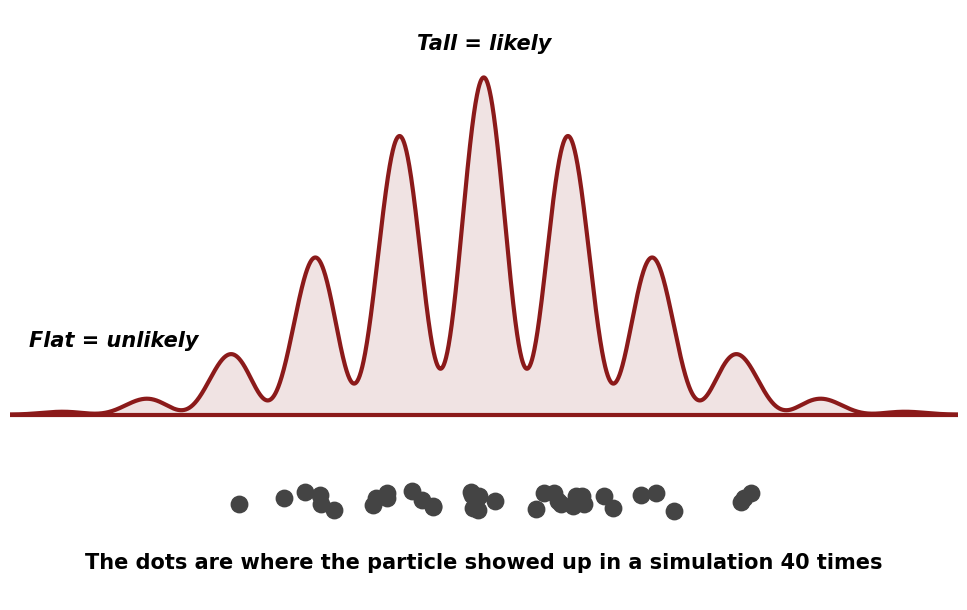

In [2]:
"""
Particle detection simulation: where a quantum particle shows up.

The curve is the probability density |psi(x)|^2 for a particle passing
through two slits (an interference pattern under a single-slit envelope).
Each dot is one simulated detection, drawn at random from that density
using inverse-transform sampling (Born rule: probability ~ |psi|^2).

Reproducible: the random seed is fixed, so anyone who runs this script
gets exactly the same 40 dots. Change SEED or N_DETECTIONS to see other runs.

Requirements: Python 3, numpy, matplotlib
Run:  python particle_detection_sim.py
"""

import numpy as np
import matplotlib.pyplot as plt

SEED = 42            # fixed so the figure is reproducible
N_DETECTIONS = 40    # number of simulated particle detections

# ---- 1. Probability density |psi(x)|^2 --------------------------------
x = np.linspace(-6, 6, 4001)
fringe_spacing = 1.0          # distance between interference peaks
envelope_width = 1.6          # width of the overall envelope
envelope = np.exp(-x**2 / (2 * envelope_width**2))
fringes = 1 + 0.75 * np.cos(2 * np.pi * x / fringe_spacing)
density = envelope * fringes
density /= density.sum() * (x[1] - x[0])   # normalize: total probability = 1

# ---- 2. Sample detections from the density (Born rule) ----------------
cdf = np.cumsum(density)
cdf /= cdf[-1]
rng = np.random.default_rng(SEED)
u = rng.random(N_DETECTIONS)
detections = np.interp(u, cdf, x)   # inverse-transform sampling

# ---- 3. Check: samples should match the density -----------------------
# Kolmogorov-Smirnov statistic between the sample and the true CDF
sample_sorted = np.sort(detections)
true_cdf_at_samples = np.interp(sample_sorted, x, cdf)
ecdf_hi = np.arange(1, N_DETECTIONS + 1) / N_DETECTIONS
ecdf_lo = np.arange(0, N_DETECTIONS) / N_DETECTIONS
ks = max(np.max(ecdf_hi - true_cdf_at_samples),
         np.max(true_cdf_at_samples - ecdf_lo))
ks_critical_05 = 1.36 / np.sqrt(N_DETECTIONS)  # 5% critical value
print(f"Mean detection position: {detections.mean():+.3f}  (curve center = 0)")
print(f"KS statistic: {ks:.3f}  (5% critical value: {ks_critical_05:.3f})")
print("Sample is consistent with the curve" if ks < ks_critical_05
      else "Sample differs from the curve")

# ---- 4. Draw the figure -----------------------------------------------
dark_red = "#8B1A1A"
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.plot(x, density, color=dark_red, lw=3)
ax.fill_between(x, density, color=dark_red, alpha=0.12)
ax.axhline(0, color=dark_red, lw=3)

# dots below the axis, with small vertical jitter so overlaps stay visible
dot_y = -0.11 + rng.uniform(-0.015, 0.015, N_DETECTIONS)
ax.scatter(detections, dot_y, s=140, color="#444444", zorder=3)

peak = density.max()
ax.text(0, peak * 1.08, "Tall = likely", ha="center",
        fontsize=15, fontweight="bold", style="italic")
ax.text(-4.3, peak * 0.2, "Flat = unlikely", ha="center",
        fontsize=15, fontweight="bold", style="italic")
ax.text(0, -0.2, f"The dots are where the particle showed up "
        f"in a simulation {N_DETECTIONS} times",
        ha="center", fontsize=15, fontweight="bold")

ax.set_xlim(-5.5, 5.5)
ax.set_ylim(-0.24, peak * 1.2)
ax.axis("off")
plt.tight_layout()
plt.savefig("particle_detection_sim.png", dpi=200)
print("Saved particle_detection_sim.png")